<a href="https://colab.research.google.com/github/JesusRosales70/Machine-Learning/blob/main/Unidad%204/Practica_3_PCA_Lending_Club_U4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine y Deep Learning
# Unidad 4
## Práctica 3: **Analisis de Componentes Principales (PCA)**
### Docente: Dr. Jose Gabriel Rodriguez Rivas
### Alumno: Jesus Armando Rosales Martinez


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
# Cargar el dataset
prestamos = pd.read_csv("prestamos_ok.csv")
# Exploración rápida
prestamos.head()

,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,...,application_type,acc_now_delinq,chargeoff_within_12_mths,delinq_amnt,pub_rec_bankruptcies,tax_liens,hardship_flag,disbursement_method,debt_settlement_flag,debt_settlement_flag_date
0,2400,2400,2400.0,36 months,15.96,84.33,C,C5,NaN,10+ years,...,Individual,0.0,0.0,0.0,0.0,0.0,N,Cash,N,NaN
1,10000,10000,10000.0,36 months,13.49,339.31,C,C1,AIR RESOURCES BOARD,10+ years,...,Individual,0.0,0.0,0.0,0.0,0.0,N,Cash,N,NaN
2,3000,3000,3000.0,36 months,18.64,109.43,E,E1,MKC Accounting,9 years,...,Individual,0.0,0.0,0.0,0.0,0.0,N,Cash,N,NaN
3,5600,5600,5600.0,60 months,21.28,152.39,F,F2,NaN,4 years,...,Individual,0.0,0.0,0.0,0.0,0.0,N,Cash,N,NaN
4,5375,5375,5350.0,60 months,12.69,121.45,B,B5,Starbucks,< 1 year,...,Individual,0.0,0.0,0.0,0.0,0.0,N,Cash,N,NaN


In [ ]:
# Crear las columnas codificadas a partir de las categóricas originales
prestamos['grade_code'] = prestamos['grade'].astype('category').cat.codes
prestamos['purpose_code'] = prestamos['purpose'].astype('category').cat.codes
prestamos['addr_state_code'] = prestamos['addr_state'].astype('category').cat.codes
prestamos['home_ownership_code'] = prestamos['home_ownership'].astype('category').cat.codes

model_columns = [
    'funded_amnt', 'int_rate', 'grade_code', 'purpose_code',
    'addr_state_code', 'home_ownership_code', 'annual_inc', 'dti',
    'revol_util', 'pub_rec_bankruptcies'
]
X = prestamos[model_columns]
X.head()

,funded_amnt,int_rate,grade_code,purpose_code,addr_state_code,home_ownership_code,annual_inc,dti,revol_util,pub_rec_bankruptcies
0,2400,15.96,2,10,2,2,12252.0,8.72,98.5,0.0
1,10000,13.49,2,8,0,2,49200.0,20.00,21.0,0.0
2,3000,18.64,4,0,0,2,48000.0,5.35,87.5,0.0
3,5600,21.28,5,10,0,1,40000.0,5.55,32.6,0.0
4,5375,12.69,1,8,5,2,15000.0,18.08,36.5,0.0


In [ ]:
# Verificar si existe la columna 'loan_status' y crear la columna objetivo 'repaid'
if 'loan_status' in prestamos.columns:
    # 1 si el préstamo está completamente pagado ('Fully Paid'), de lo contrario 0
    prestamos['repaid'] = (prestamos['loan_status'] == 'Fully Paid').astype(int)

y = prestamos['repaid']
y.head()

,repaid
0,1
1,1
2,1
3,0
4,0


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-1.29599074,  0.75729524,  0.30412804, ..., -0.77773021,
         1.58739354, -0.16266678],
       [-0.34815653,  0.16899682,  0.30412804, ...,  0.95744833,
        -1.29897836, -0.16266678],
       [-1.22116172,  1.39561093,  1.73071292, ..., -1.29613018,
         1.17771494, -0.16266678],
       ...,
       [-0.09872647, -1.46728259, -1.12245685, ...,  1.49430765,
        -1.36601668, -0.16266678],
       [-0.89690265, -1.46728259, -1.12245685, ...,  0.1237012 ,
        -1.00475464, -0.16266678],
       [-0.59758658,  1.30272171,  1.01742048, ...,  0.66979019,
        -0.88929977,         nan]], shape=(2988, 10))

In [ ]:
from sklearn.impute import SimpleImputer

# Imputar los valores NaN en los datos escalados (usando la media de cada columna)
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X_scaled)

# Inicializar PCA y especificar el número de componentes principales deseados
pca = PCA(n_components=2)  # Elegimos 2 componentes para visualización
X_pca = pca.fit_transform(X_imputed)

# Mostrar la proporción de varianza explicada por cada componente
explained_variance = pca.explained_variance_ratio_
print("Proporción de varianza explicada por cada componente:", explained_variance)
print("Varianza explicada acumulada:", np.cumsum(explained_variance))

Proporción de varianza explicada por cada componente: [0.24810226 0.16497135]
Varianza explicada acumulada: [0.24810226 0.41307361]


In [ ]:
# Inicializar PCA y especificar el número de componentes principales deseados
pca = PCA(n_components=6)  # Elegimos 6 componentes
# Usamos X_imputed en lugar de X_scaled para evitar el error de NaNs
X_pca = pca.fit_transform(X_imputed)
# Mostrar la proporción de varianza explicada por cada componente
explained_variance = pca.explained_variance_ratio_
print("Proporción de varianza explicada por cada componente:", explained_variance)
print("Varianza explicada acumulada:", np.cumsum(explained_variance))

Proporción de varianza explicada por cada componente: [0.24810226 0.16497135 0.11334073 0.09998602 0.09858549 0.08668839]
Varianza explicada acumulada: [0.24810226 0.41307361 0.52641434 0.62640036 0.72498585 0.81167423]


In [ ]:
# Coeficientes de las variables
componentes = pd.DataFrame(
pca.components_,
columns=X.columns,
index=[f'PC{i+1}' for i in range(pca.n_components_)]
)
print("Contribución de variables a cada componente:")
print(componentes)

Contribución de variables a cada componente:
     funded_amnt  int_rate  grade_code  purpose_code  addr_state_code  \
PC1     0.298694  0.595941    0.590342     -0.112091        -0.009932   
PC2     0.446034 -0.032282   -0.003048      0.106994         0.115693   
PC3    -0.238458  0.191618    0.192607      0.664965        -0.145742   
PC4    -0.093443 -0.003220    0.000994     -0.057870         0.734144   
PC5    -0.042428  0.099008    0.098352      0.323051         0.625650   
PC6     0.074475  0.017331    0.023436      0.563178        -0.174062   

     home_ownership_code  annual_inc       dti  revol_util  \
PC1             0.032250    0.139994  0.132628    0.394195   
PC2            -0.457842    0.587461 -0.359274   -0.297682   
PC3             0.145451   -0.059843 -0.437022   -0.087270   
PC4            -0.260915   -0.083122  0.202378    0.016301   
PC5             0.276567   -0.079804 -0.096591   -0.073028   
PC6            -0.450671   -0.142428  0.627693   -0.074435   

     pub

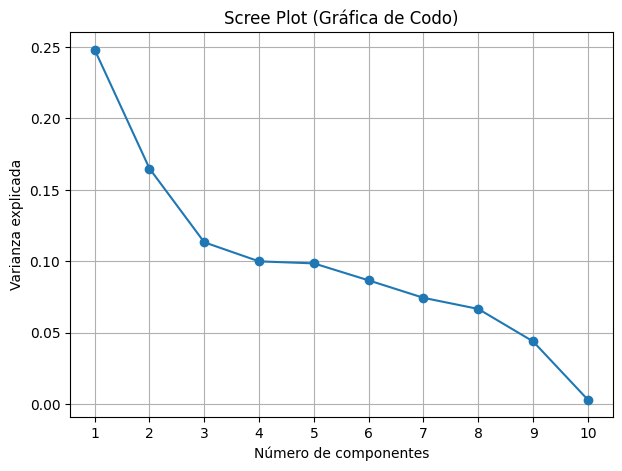

Varianza por componente: [0.24810226 0.16497135 0.11334073 0.09998602 0.09858549 0.08668839
 0.07448037 0.06670038 0.04397849 0.00316652]
Varianza acumulada: [0.24810226 0.41307361 0.52641434 0.62640036 0.72498585 0.81167423
 0.88615461 0.95285499 0.99683348 1.        ]


In [ ]:
pca_full = PCA()
pca_full.fit(X_imputed)
plt.figure(figsize=(7,5))
plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_,
    marker='o'
)
plt.xticks(range(1, len(pca_full.explained_variance_ratio_) + 1))
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada")
plt.title("Scree Plot (Gráfica de Codo)")
plt.grid(True)
plt.show()
print("Varianza por componente:", pca_full.explained_variance_ratio_)
print("Varianza acumulada:", pca_full.explained_variance_ratio_.cumsum())

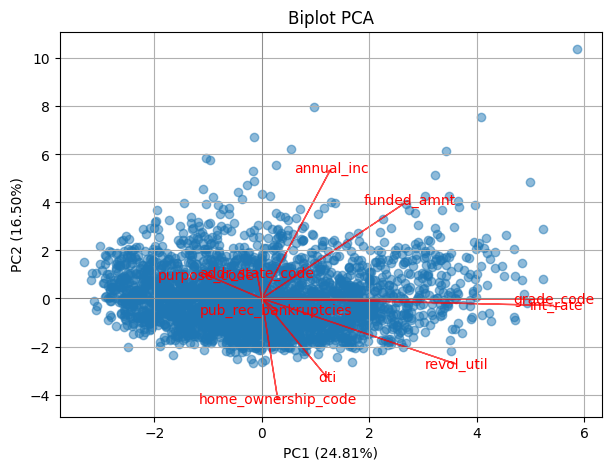

In [ ]:
pca = PCA(n_components=6)  # Definimos el PCA con 6 componentes
components = pca.fit_transform(X_imputed)   # Usamos X_imputed para evitar errores de NaN
# Componentes
PC1 = components[:, 0]
PC2 = components[:, 1]
PC3 = components[:, 2]
PC4 = components[:, 3]
PC5 = components[:, 4]
PC6 = components[:, 5]
loadings = pca.components_.T
# loadings (vectores)
variables = X.columns   # Guarda los nombres de las variables originales
plt.figure(figsize=(7,5))
# Graficar puntos (scores)
plt.scatter(PC1, PC2, alpha=0.5)
# Etiquetas de ejes
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)")
# Graficar vectores (loadings) con indentación correcta
for i, var in enumerate(variables):
    plt.arrow(0, 0,
              loadings[i,0]*9,   # multiplicador para mejorar visualización
              loadings[i,1]*9,
              color='red',
              alpha=0.7,
              head_width=0.05)
    plt.text(loadings[i,0]*9.2,
             loadings[i,1]*9.2,
             var, color='red', ha='center', va='center')
plt.title("Biplot PCA")
plt.grid(True)
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.show()

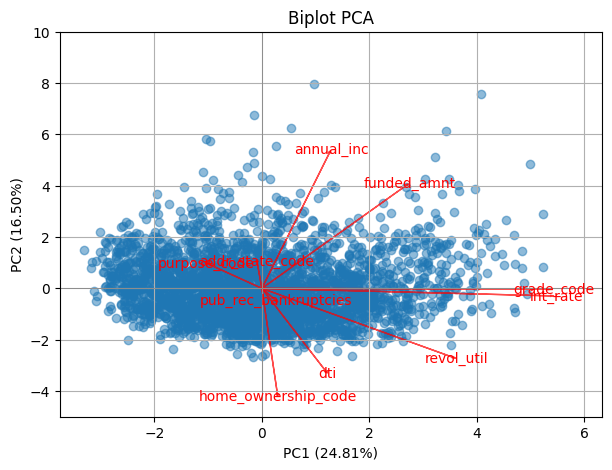

In [ ]:
pca = PCA(n_components=6)  # Definimos el PCA con 6 componentes
components = pca.fit_transform(X_imputed)   # Usamos X_imputed para evitar errores de NaN
# Componentes
PC1 = components[:, 0]
PC2 = components[:, 1]
PC3 = components[:, 2]
PC4 = components[:, 3]
PC5 = components[:, 4]
PC6 = components[:, 5]
loadings = pca.components_.T
# loadings (vectores)
variables = X.columns   # Guarda los nombres de las variables originales
plt.figure(figsize=(7,5))
# Graficar puntos (scores)
plt.scatter(PC1, PC2, alpha=0.5)
# Etiquetas de ejes
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)")
plt.ylim(-5, 10)  # Ajustar
# Graficar vectores (loadings) con indentación corregida
for i, var in enumerate(variables):
    plt.arrow(0, 0,
              loadings[i,0]*9,   # multiplicador para mejorar visualización
              loadings[i,1]*9,
              color='red',
              alpha=0.7,
              head_width=0.05)
    plt.text(loadings[i,0]*9.2,
             loadings[i,1]*9.2,
             var, color='red', ha='center', va='center')
plt.title("Biplot PCA")
plt.grid(True)
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.show()

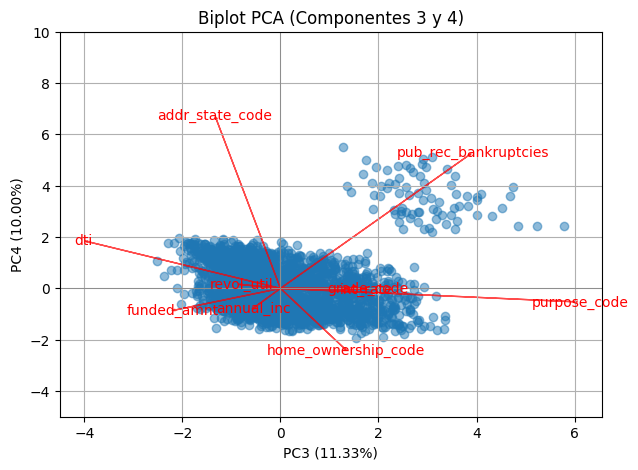

In [ ]:
pca = PCA(n_components=6)  # Definimos el PCA con 6 componentes
components = pca.fit_transform(X_imputed)   # Usamos X_imputed para evitar el error de NaNs
# Componentes
PC1 = components[:, 0]
PC2 = components[:, 1]
PC3 = components[:, 2]
PC4 = components[:, 3]
PC5 = components[:, 4]
PC6 = components[:, 5]
loadings = pca.components_.T
# loadings (vectores)
variables = X.columns   # Guarda los nombres de las variables originales
plt.figure(figsize=(7,5))
# Graficar puntos (scores)
plt.scatter(PC3, PC4, alpha=0.5 )
# Etiquetas de ejes
plt.xlabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.2f}%)")
plt.ylabel(f"PC4 ({pca.explained_variance_ratio_[3]*100:.2f}%)")
plt.ylim(-5, 10)  # Ajustar
# Graficar vectores (loadings)
for i, var in enumerate(variables):
    plt.arrow(0, 0,
              loadings[i,2]*9,   #  multiplicador para mejorar visualización
              loadings[i,3]*9,
              color='red',
              alpha=0.7,
              head_width=0.05)
    plt.text(loadings[i,2]*9.2,
             loadings[i,3]*9.2,
             var, color='red', ha='center', va='center')
plt.title("Biplot PCA (Componentes 3 y 4)")
plt.grid(True)
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.show()